# RFX / Notes / 00 — Rate–FX data: coverage, co-movement by hour, hedge ratios through time

Protocol: [`RFX 001`](../../../discussions/Rate_FX_Pairs/001_claude_rfx01_preregistration.md). Descriptive only, nothing is selected here. Uses **H1** (2016–2020) so the second half stays unseen until its own notebooks.

- Bars per pairing and year (5-minute bars where every leg was quoted).
- Correlation of 5-minute FX returns with each bond's returns, by UTC hour: when the link is strong.
- Rolling 60-day hedge ratios (no-intercept regression of FX returns on bond returns), to see whether the link is stable.

In [1]:
STUDY = "RFX"
WINDOW = "H1"

import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RFX_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RFX_SYNTH_DIR") or tempfile.mkdtemp(prefix="rfx_")
    os.environ["RFX_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F
from equity_trading import bond_seasonality as B
from equity_trading import bond_fx as X

cfg = X.BFXConfig()
if SYNTHETIC:
    cfg = replace(cfg, n_placebo=2, n_boot=2_000)
PAIRS = list(X.STUDIES[STUDY].pairings)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200)
OUT = Path.cwd() / ("00_synthetic" if SYNTHETIC else "00"); OUT.mkdir(exist_ok=True)
START, END = X.STUDIES[STUDY].windows[WINDOW]

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"])
    if not (base / "Databento").exists():
        X.write_synthetic_rates(base, dt.date(2015, 12, 28), dt.date(2025, 12, 31), seed=5)

## 1. Bars

In [3]:
legs = {}
frames = {p: X.frame(p, WINDOW, cfg, legs, study=STUDY) for p in PAIRS}
print(f"window {WINDOW} {START} -> {END}")
display(pd.DataFrame([{"pairing": p, "bonds": " + ".join(X.BOND_SHORT[b] for b in fr.bonds), "bars": fr.n,
                       "days": len(np.unique(fr.day)), "bars per day (median)": fr.bars_per_day,
                       "counted years": ", ".join(map(str, X.counted_years(fr, cfg)))} for p, fr in frames.items()]))
display(pd.DataFrame([{"leg": s, "file share": round(l.file_share, 4), "missing days": len(l.missing),
                       "spike minutes": len(l.spikes), "zero-price minutes": l.bad_quotes, "contract switches": int((l.rolls["method"] != "extra").sum()) if len(l.rolls) else 0,
                       "switch methods": l.rolls.loc[l.rolls["method"] != "extra", "method"].value_counts().to_dict() if len(l.rolls) else {}}
                      for s, l in legs.items()]))
assert all(l.file_share >= cfg.min_file_share for l in legs.values()), "fewer than 95% of weekday files for a leg"
cov = pd.concat({p: X.coverage_table(fr) for p, fr in frames.items()}, names=["pairing", "year"])
display(cov.round(1)); cov.to_csv(OUT / "01_coverage.csv")

window H1 2016-01-01 -> 2020-12-31


,pairing,bonds,bars,days,bars per day (median),counted years
0,EURUSD,ZT + ZF,345681,1553,277.0,"2016, 2017, 2018, 2019, 2020"
1,GBPUSD,ZT + ZF,343742,1545,277.0,"2016, 2017, 2018, 2019, 2020"
2,USDJPY,ZT + ZF,343795,1545,277.0,"2016, 2017, 2018, 2019, 2020"


,leg,file share,missing days,spike minutes,zero-price minutes,contract switches,switch methods
0,EURUSD,1.0000,0,2,0,0,{}
1,ZT,0.9954,6,0,0,20,{'instrument_change': 20}
2,ZF,0.9954,6,0,0,22,{'instrument_change': 22}
3,GBPUSD,1.0000,0,23,0,0,{}
4,USDJPY,1.0000,0,13,0,0,{}


bars  days  bars_per_day
pairing year                           
EURUSD  2016  69074   309         223.5
        2017  69152   311         222.4
        2018  68849   311         221.4
        2019  69212   311         222.5
        2020  69394   311         223.1
GBPUSD  2016  67980   305         222.9
        2017  68875   310         222.2
        2018  68848   311         221.4
        2019  68650   309         222.2
        2020  69389   310         223.8
USDJPY  2016  67746   304         222.8
        2017  69151   310         223.1
        2018  68847   311         221.4
        2019  68934   310         222.4
        2020  69117   310         223.0

### Month by month

Valid bars, bars with a usable 5-minute return, and the share of those returns where a bond did not move at all. A share near 1 means stale prices marked as quoted: the hedge ratio cannot be estimated there.

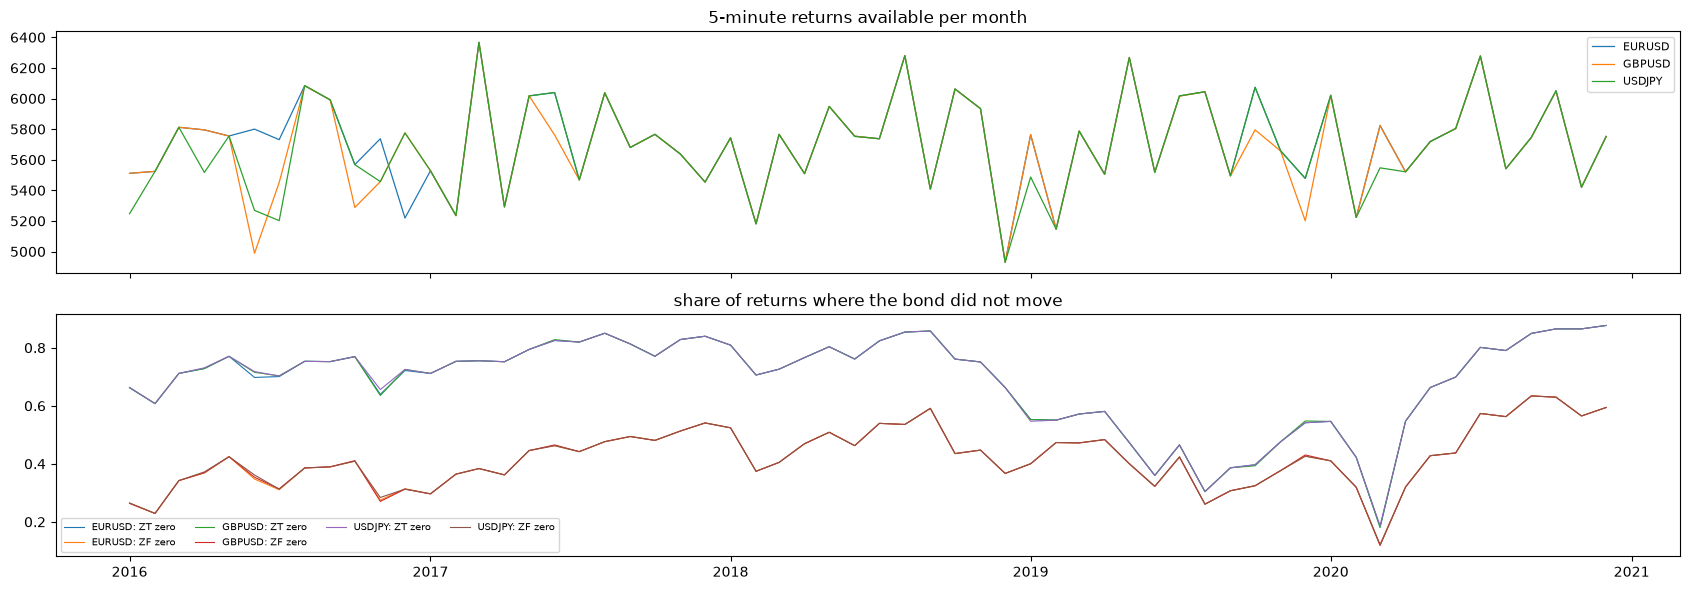

bars  days  returns  share ZT zero  share ZF zero  share FX zero
pairing month                                                                    
EURUSD  2016-01  5546    25     5511          0.662          0.264          0.006
        2016-02  5556    25     5524          0.608          0.229          0.005
        2016-03  5864    26     5812          0.712          0.342          0.010
        2016-04  5837    25     5795          0.728          0.369          0.012
        2016-05  5815    27     5755          0.771          0.425          0.010
        2016-06  5851    26     5800          0.698          0.348          0.010
        2016-07  5777    26     5731          0.701          0.311          0.012
        2016-08  6134    27     6084          0.753          0.386          0.012
        2016-09  6048    26     5991          0.752          0.390          0.013
        2016-10  5612    26     5568          0.770          0.409          0.013
        2016-11  5766    26     5737          0.640          0.275          0.011
        2016-12  5268    24     5219          0.722          0.314          0.010
GBPUSD  2016-01  5546    25     5511          0.662          0.264          0.006
        2016-02  5556    25     5524          0.608          0.229          0.005
        2016-03  5864    26     5812          0.712          0.342          0.009
        2016-04  5837    25     5795          0.728          0.369          0.007
        2016-05  5815    27     5755          0.771          0.425          0.009
        2016-06  5039    23     4989          0.715          0.354          0.005
        2016-07  5497    25     5451          0.703          0.314          0.004
        2016-08  6134    27     6084          0.753          0.386          0.008
        2016-09  6048    26     5991          0.752          0.390          0.008
        2016-10  5332    25     5288          0.769          0.411          0.007
        2016-11  5486    25     5457          0.636          0.270          0.008
        2016-12  5826    26     5775          0.725          0.313          0.006
USDJPY  2016-01  5282    24     5247          0.663          0.265          0.005
        2016-02  5556    25     5524          0.608          0.229          0.004
        2016-03  5864    26     5812          0.712          0.342          0.007
        2016-04  5558    24     5517          0.731          0.372          0.007
        2016-05  5815    27     5755          0.771          0.425          0.011
        2016-06  5319    24     5269          0.718          0.362          0.009
        2016-07  5246    24     5202          0.702          0.313          0.007
        2016-08  6134    27     6084          0.753          0.386          0.012
        2016-09  6048    26     5991          0.752          0.390          0.009
        2016-10  5612    26     5568          0.770          0.409          0.012
        2016-11  5486    25     5457          0.656          0.284          0.006
        2016-12  5826    26     5775          0.725          0.313          0.008

In [4]:
mon = pd.concat({p: X.monthly_diagnostics(fr) for p, fr in frames.items()}, names=["pairing", "month"])
mon.to_csv(OUT / "01_monthly.csv")
fig, axes = plt.subplots(2, 1, figsize=(17, 6), sharex=True)
for p in PAIRS:
    m = mon.loc[p]
    x = m.index.to_timestamp()
    axes[0].plot(x, m["returns"], lw=0.9, label=p)
    for c in [c for c in m.columns if c.startswith("share") and not c.endswith("FX zero")]:
        axes[1].plot(x, m[c], lw=0.8, label=f"{p}: {c.replace('share ', '')}")
axes[0].set_title("5-minute returns available per month"); axes[0].legend(fontsize=8)
axes[1].set_title("share of returns where the bond did not move"); axes[1].legend(fontsize=7, ncol=4)
plt.tight_layout(); plt.savefig(OUT / "01_monthly.png", dpi=110); plt.show()
display(mon[mon.index.get_level_values("month").year == START.year].round(3))

## 2. Co-movement by hour (UTC)

Correlation of 5-minute returns. A rate future's price rises when US rates fall, which weakens the dollar, so the expected signs are positive for EURUSD and GBPUSD and negative for USDJPY.

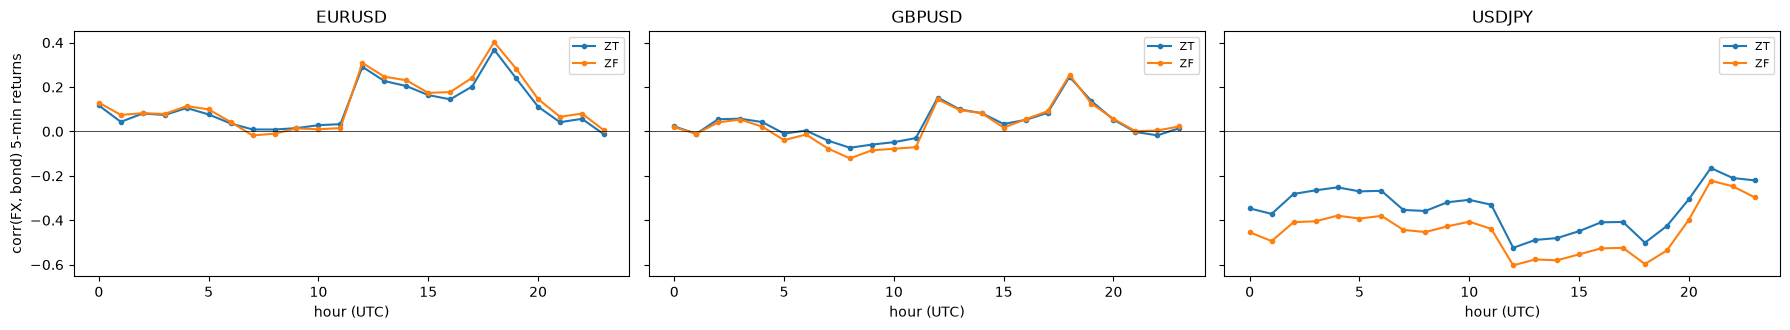

In [5]:
hc = pd.concat({p: X.hourly_correlation(fr) for p, fr in frames.items()}, names=["pairing"]).reset_index(level=0)
fig, axes = plt.subplots(1, len(PAIRS), figsize=(18, 3.4), sharey=True)
for ax, p in zip(axes, PAIRS):
    h = hc[hc["pairing"] == p]
    for b in X.STUDIES[STUDY].pairings[p]:
        ax.plot(h["hour_utc"], h[X.BOND_SHORT[b]], marker="o", ms=3, label=X.BOND_SHORT[b])
    ax.axhline(0, color="black", lw=0.5); ax.set_title(p); ax.set_xlabel("hour (UTC)"); ax.legend(fontsize=8)
axes[0].set_ylabel("corr(FX, bond) 5-min returns")
plt.tight_layout(); plt.savefig(OUT / "02_hourly_correlation.png", dpi=110); plt.show()
hc.to_csv(OUT / "02_hourly_correlation.csv", index=False)

## 3. Hedge ratios through time

Rolling 60-day no-intercept regression of FX returns on bond returns, sampled once per day.

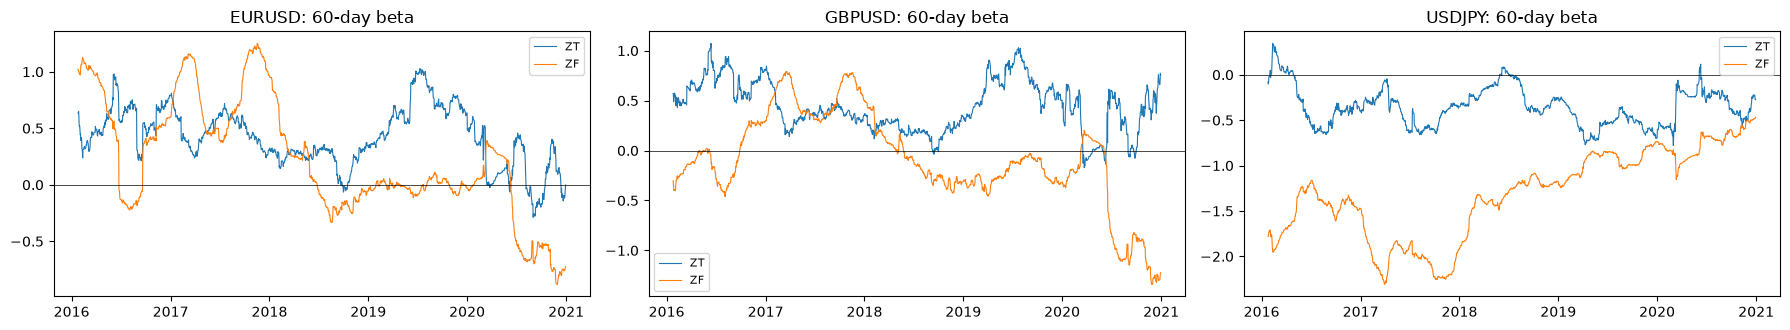

In [6]:
fig, axes = plt.subplots(1, len(PAIRS), figsize=(18, 3.4))
for ax, (p, fr) in zip(axes, frames.items()):
    ry, rX = fr.returns()
    beta = X.rolling_beta(ry, rX, int(60 * fr.bars_per_day))
    last = np.r_[np.flatnonzero(fr.day[1:] != fr.day[:-1]), fr.n - 1]
    for j, b in enumerate(fr.bonds):
        ax.plot(pd.to_datetime(fr.day[last]), beta[last, j], lw=0.8, label=X.BOND_SHORT[b])
    ax.axhline(0, color="black", lw=0.5); ax.set_title(f"{p}: 60-day beta"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "03_rolling_beta.png", dpi=110); plt.show()